# Assignment 5 – Sentiment Analysis of Financial Tweets
**Natural Language Processing (NLP), Summer Term 2025 – University of Tübingen**

**Author:** *Albert Borchardt (albert.borchardt@student.uni-tuebingen.de, 6871987)*

---

**Goal:**  
Automatically classify sentiment (bullish / bearish / neutral) in tweets and short financial news messages.

I applied and compare two approaches:
- **Logistic Regression** (with TF-IDF and engineered features)
- **Neural Network** (MLP with FinBERT embeddings and engineered features)

Dataset: `twitter-financial-news` (https://huggingface.co/datasets/zeroshot/twitter-financial-news-sentiment)


### ============================================
# Imports
### ============================================

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from datasets import load_dataset
import re
import gc
import nltk
nltk.download('punkt')
nltk.download('stopwords')
nltk.download('wordnet')
from nltk.tokenize import word_tokenize
from nltk.corpus import stopwords
from nltk.stem import WordNetLemmatizer
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.model_selection import train_test_split, GridSearchCV, StratifiedKFold
from sklearn.metrics import classification_report, confusion_matrix, accuracy_score, f1_score
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier, VotingClassifier
from sklearn.neural_network import MLPClassifier
from sklearn.preprocessing import StandardScaler
from imblearn.over_sampling import SMOTE
import torch
from transformers import AutoTokenizer, AutoModel
from tqdm import tqdm
from collections import Counter
from wordcloud import WordCloud
import emoji
from scipy.sparse import hstack
import warnings
warnings.filterwarnings('ignore')

[nltk_data] Downloading package punkt to /home/albert/nltk_data...
[nltk_data]   Package punkt is already up-to-date!
[nltk_data] Downloading package stopwords to /home/albert/nltk_data...
[nltk_data]   Package stopwords is already up-to-date!
[nltk_data] Downloading package wordnet to /home/albert/nltk_data...
[nltk_data]   Package wordnet is already up-to-date!


### ============================================
# Load Dataset and Overview
### ============================================


In [2]:
dataset = load_dataset("zeroshot/twitter-financial-news-sentiment")
train_dataset = dataset["train"]
valid_dataset = dataset["validation"]
train_df = train_dataset.to_pandas()
test_df = valid_dataset.to_pandas()  
print("=== DATASET OVERVIEW ===")
print(f"Train shape: {train_df.shape}")
print(f"Test shape: {test_df.shape}")
print("\nFirst few entries:")
print(train_df.head())
label_map = {0: "Bearish", 1: "Bullish", 2: "Neutral"}
train_df['sentiment'] = train_df['label'].map(label_map)
test_df['sentiment'] = test_df['label'].map(label_map)

=== DATASET OVERVIEW ===
Train shape: (9543, 2)
Test shape: (2388, 2)

First few entries:
                                                text  label
0  $BYND - JPMorgan reels in expectations on Beyo...      0
1  $CCL $RCL - Nomura points to bookings weakness...      0
2  $CX - Cemex cut at Credit Suisse, J.P. Morgan ...      0
3  $ESS: BTIG Research cuts to Neutral https://t....      0
4  $FNKO - Funko slides after Piper Jaffray PT cu...      0


### ===========================================
# Data Exploration
### ===========================================

Train set class distribution:
sentiment
Neutral    6178
Bullish    1923
Bearish    1442
Name: count, dtype: int64

Test set class distribution:
sentiment
Neutral    1566
Bullish     475
Bearish     347
Name: count, dtype: int64


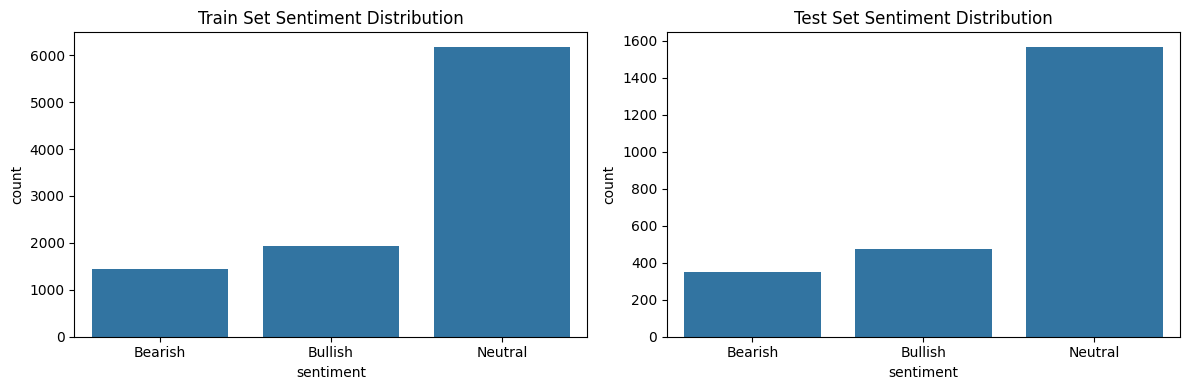

Bearish example: $BYND - JPMorgan reels in expectations on Beyond Meat https://t.co/bd0xbFGjkT
Bullish example: $ALTG: Dougherty & Company starts at Buy
Neutral example: $LB - MKM Partners puts a number on Victoria's Secret https://t.co/VSzHLqLBgE

Train text length (words):
count    9543.00
mean       12.18
std         4.67
min         1.00
25%         9.00
50%        11.00
75%        15.00
max        32.00
Name: text_length, dtype: float64


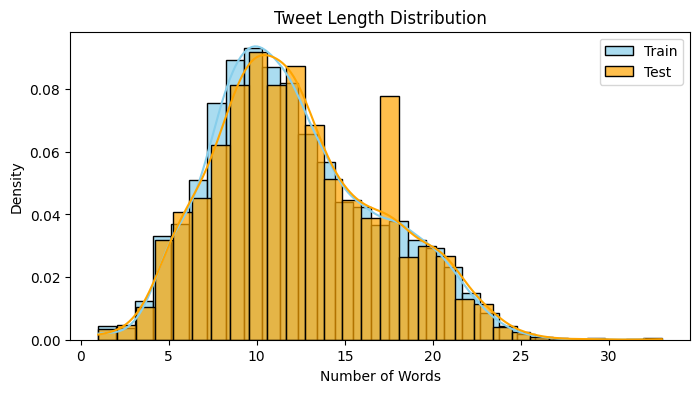

In [3]:
train_counts = train_df['sentiment'].value_counts()
test_counts = test_df['sentiment'].value_counts()

print("Train set class distribution:")
print(train_counts)
print("\nTest set class distribution:")
print(test_counts)

fig, ax = plt.subplots(1, 2, figsize=(12,4))
sns.countplot(x='sentiment', data=train_df, ax=ax[0])
ax[0].set_title('Train Set Sentiment Distribution')
sns.countplot(x='sentiment', data=test_df, ax=ax[1])
ax[1].set_title('Test Set Sentiment Distribution')
plt.tight_layout()
plt.show()

for sentiment in label_map.values():
    sample = train_df[train_df['sentiment'] == sentiment]['text'].iloc[0]
    print(f"{sentiment} example: {sample}")

train_df['text_length'] = train_df['text'].apply(lambda x: len(str(x).split()))
test_df['text_length'] = test_df['text'].apply(lambda x: len(str(x).split()))
print("\nTrain text length (words):")
print(train_df['text_length'].describe().round(2))

plt.figure(figsize=(8,4))
sns.histplot(train_df['text_length'], kde=True, bins=30, color="skyblue", label='Train', stat='density', alpha=0.7)
sns.histplot(test_df['text_length'], kde=True, bins=30, color="orange", label='Test', stat='density', alpha=0.7)
plt.legend()
plt.title('Tweet Length Distribution')
plt.xlabel('Number of Words')
plt.ylabel('Density')
plt.show()

### ===========================================
# Text Preprocessing and Tokenization
### ===========================================

Original:  $BYND - JPMorgan reels in expectations on Beyond Meat https://t.co/bd0xbFGjkT
Processed: TICKER_SYMBOL jpmorgan reel expectation beyond meat
--------------------------------------------------------------------------------
Original:  $CCL $RCL - Nomura points to bookings weakness at Carnival and Royal Caribbean https://t.co/yGjpT2ReD3
Processed: TICKER_SYMBOL TICKER_SYMBOL nomura point booking weakness carnival royal caribbean
--------------------------------------------------------------------------------
Original:  $CX - Cemex cut at Credit Suisse, J.P. Morgan on weak building outlook https://t.co/KN1g4AWFIb
Processed: TICKER_SYMBOL cemex cut credit suisse morgan weak building outlook
--------------------------------------------------------------------------------
Total tokens after preprocessing: 83,437
Unique tokens: 13,422
Vocabulary size (filtered): 12,988

Top 10 stock tickers:
$SPY: 26
$COMDX: 23
$TSLA: 20
$SCANX: 16
$SUMRX: 13
$NVDA: 12
$USO: 12
$MDCO: 11
$ECONX: 11


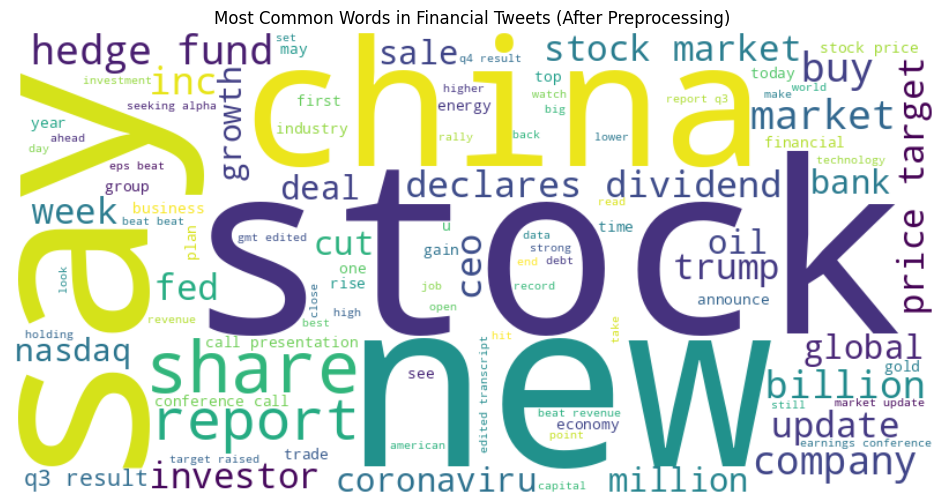

In [4]:
stop_words = set(stopwords.words('english'))
financial_negations = {'not', 'no', 'nor', 'never', 'nothing', 'nowhere', 'neither'}
financial_indicators = {'up', 'down', 'high', 'low', 'buy', 'sell', 'rise', 'fall', 'gain', 'loss'}
stop_words = stop_words - financial_negations - financial_indicators

lemmatizer = WordNetLemmatizer()

def advanced_preprocess(text):
    text = str(text).lower()
    text = re.sub(r'http\S+|www\S+|https\S+', ' ', text)
    text = re.sub(r'([+-]?\d+\.?\d*%)', r' PERCENTAGE_INDICATOR ', text)
    text = re.sub(r'\$(\d+\.?\d*[kmb]?)', r' DOLLAR_AMOUNT ', text)
    ticker_pattern = r'\$([A-Za-z]{2,5})'
    text = re.sub(ticker_pattern, ' TICKER_SYMBOL ', text)
    text = re.sub(r'#([a-zA-Z0-9_]+)', r'HASHTAG_\1', text)
    text = emoji.replace_emoji(text, replace=' EMOJI_INDICATOR ')
    text = re.sub(r'[^\w\s]', ' ', text)
    text = re.sub(r'\s+', ' ', text)
    tokens = word_tokenize(text)
    tokens = [lemmatizer.lemmatize(token) for token in tokens if token not in stop_words and len(token) > 1]
    result = ' '.join(tokens)
    return result if result else ''

train_df['text_clean'] = train_df['text'].apply(advanced_preprocess)
test_df['text_clean'] = test_df['text'].apply(advanced_preprocess)

for i in range(3):
    print("Original: ", train_df['text'].iloc[i])
    print("Processed:", train_df['text_clean'].iloc[i])
    print("-" * 80)

all_tokens = ' '.join(train_df['text_clean']).split()
filtered_tokens = [token for token in all_tokens if not token.startswith(('TICKER_', 'HASHTAG_', 'PERCENTAGE_', 'DOLLAR_', 'EMOJI_'))]

print(f"Total tokens after preprocessing: {len(all_tokens):,}")
print(f"Unique tokens: {len(set(all_tokens)):,}")
print(f"Vocabulary size (filtered): {len(set(filtered_tokens)):,}")

all_tickers = []
for text in train_df['text']:
    tickers = re.findall(r'\$([A-Za-z]{2,5})', text)
    all_tickers.extend([t.upper() for t in tickers])
ticker_freq = Counter(all_tickers)
print("\nTop 10 stock tickers:")
for ticker, count in ticker_freq.most_common(10):
    print(f"${ticker}: {count}")

all_hashtags = []
for text in train_df['text']:
    hashtags = re.findall(r'#([a-zA-Z0-9_]+)', text)
    all_hashtags.extend([h.lower() for h in hashtags])
hashtag_freq = Counter(all_hashtags)
print("\nTop 10 hashtags:")
for hashtag, count in hashtag_freq.most_common(10):
    print(f"#{hashtag}: {count}")

wordcloud = WordCloud(width=800, height=400, background_color='white', max_words=100, colormap='viridis').generate(' '.join(filtered_tokens))
plt.figure(figsize=(12, 6))
plt.imshow(wordcloud, interpolation='bilinear')
plt.axis('off')
plt.title("Most Common Words in Financial Tweets (After Preprocessing)")
plt.show()


### ===========================================
# Feature Engineering
### ===========================================

### Financial Features & TF-IDF

In [5]:
bullish_words = [
    'bullish', 'bull', 'buy', 'strong', 'up', 'rise', 'gain', 'profit', 'positive',
    'beat', 'upgrade', 'outperform', 'rally', 'surge', 'climb', 'jump', 'boost',
    'growth', 'increase', 'long', 'record', 'optimism', 'breakout', 'momentum', 'expansion',
    'rebound', 'support', 'recover', 'soar', 'exceed', 'surpass', 'winner', 'skyrocket'
]
bearish_words = [
    'bearish', 'bear', 'sell', 'weak', 'down', 'fall', 'loss', 'negative',
    'miss', 'downgrade', 'underperform', 'decline', 'drop', 'plunge', 'crash',
    'short', 'decrease', 'reduce', 'lower', 'resistance', 'fear', 'panic', 'slowdown',
    'collapse', 'concern', 'slump', 'lag', 'pullback', 'default', 'sink', 'uncertainty'
]

def extract_financial_features(df):
    df['bullish_word_count'] = df['text'].apply(lambda x: sum(1 for word in bullish_words if word in str(x).lower().split()))
    df['bearish_word_count'] = df['text'].apply(lambda x: sum(1 for word in bearish_words if word in str(x).lower().split()))
    df['sentiment_score'] = (df['bullish_word_count'] - df['bearish_word_count']) / (df['bullish_word_count'] + df['bearish_word_count'] + 1)
    df['has_ticker'] = df['text'].str.contains(r'\$[A-Z]+', regex=True).astype(int)
    df['has_percentage'] = df['text'].str.contains(r'\d+%', regex=True).astype(int)
    df['has_dollar_amount'] = df['text'].str.contains(r'\$\d+', regex=True).astype(int)
    df['has_hashtag'] = df['text'].str.contains(r'#\w+', regex=True).astype(int)
    df['exclamation_count'] = df['text'].str.count('!')
    df['question_count'] = df['text'].str.count('\?')
    df['caps_ratio'] = df['text'].apply(lambda x: sum(1 for c in str(x) if c.isupper()) / (len(str(x)) + 1))
    return df

train_df = extract_financial_features(train_df)
test_df = extract_financial_features(test_df)

feature_columns = [
    'bullish_word_count', 'bearish_word_count', 'sentiment_score',
    'has_ticker', 'has_percentage', 'has_dollar_amount',
    'has_hashtag', 'exclamation_count', 'question_count', 'caps_ratio'
]

stats = train_df[feature_columns].describe().T[['mean', 'std', 'min', '50%', 'max']]
stats = stats.rename(
    columns={
        'mean': 'Mittelwert',
        'std': 'Std',
        'min': 'Min',
        '50%': 'Median',
        'max': 'Max'
    }
)
display(stats.round(3))

tfidf_vectorizer = TfidfVectorizer(
    max_features=8000,
    ngram_range=(1, 3),
    min_df=2,
    max_df=0.95,
    sublinear_tf=True,
    strip_accents='unicode',
    lowercase=True,
    token_pattern=r'\b\w+\b'
)
X_train_tfidf = tfidf_vectorizer.fit_transform(train_df['text_clean'])
X_test_tfidf = tfidf_vectorizer.transform(test_df['text_clean'])

print(f"TF-IDF matrix shape (train): {X_train_tfidf.shape}")
print(f"TF-IDF matrix shape (test): {X_test_tfidf.shape}")
print(f"Feature density: {X_train_tfidf.nnz / (X_train_tfidf.shape[0] * X_train_tfidf.shape[1]):.4f}")

feature_names = tfidf_vectorizer.get_feature_names_out()
print("Sample TF-IDF features:", ", ".join(feature_names[:10]))
sample_trigrams = [f for f in feature_names if len(f.split()) == 3][:5]
print("Sample trigram features:", ", ".join(sample_trigrams))

,Mittelwert,Std,Min,Median,Max
bullish_word_count,0.166,0.411,0.00,0.000,3.000
bearish_word_count,0.064,0.258,0.00,0.000,3.000
sentiment_score,0.047,0.224,-0.75,0.000,0.750
has_ticker,0.150,0.357,0.00,0.000,1.000
has_percentage,0.087,0.282,0.00,0.000,1.000
has_dollar_amount,0.111,0.314,0.00,0.000,1.000
has_hashtag,0.094,0.292,0.00,0.000,1.000
exclamation_count,0.017,0.258,0.00,0.000,14.000
question_count,0.058,0.246,0.00,0.000,6.000
caps_ratio,0.121,0.080,0.00,0.113,0.867


TF-IDF matrix shape (train): (9543, 8000)
TF-IDF matrix shape (test): (2388, 8000)
Feature density: 0.0013
Sample TF-IDF features: 00, 000, 000 000, 000 crore, 000 job, 000 order, 000 order cybertruck, 000 point, 000 year, 00am
Sample trigram features: 000 order cybertruck, 10 00pm gmt, 10 story 10, 11 25 19, 11 25 ticker_symbol


### FinBERT Embeddings


In [6]:
def get_finbert_embeddings(texts, model_name='ProsusAI/finbert', batch_size=8, max_length=128):
    import torch
    from transformers import AutoTokenizer, AutoModel
    import numpy as np
    from tqdm import tqdm

    device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
    try:
        tokenizer = AutoTokenizer.from_pretrained(model_name)
        model = AutoModel.from_pretrained(model_name)
        model = model.to(device)
        model.eval()
    except:
        model_name = 'distilbert-base-uncased'
        tokenizer = AutoTokenizer.from_pretrained(model_name)
        model = AutoModel.from_pretrained(model_name)
        model = model.to(device)
        model.eval()
    
    embeddings = []
    with torch.no_grad():
        for i in tqdm(range(0, len(texts), batch_size), desc="Generating BERT embeddings"):
            batch_texts = texts[i:i+batch_size]
            encoded = tokenizer(
                batch_texts,
                return_tensors='pt',
                truncation=True,
                padding='max_length',
                max_length=max_length
            )
            input_ids = encoded['input_ids'].to(device)
            attention_mask = encoded['attention_mask'].to(device)
            outputs = model(input_ids=input_ids, attention_mask=attention_mask)
            token_embeddings = outputs.last_hidden_state
            attention_mask_expanded = attention_mask.unsqueeze(-1).expand(token_embeddings.size()).float()
            sum_embeddings = torch.sum(token_embeddings * attention_mask_expanded, 1)
            sum_mask = torch.clamp(attention_mask_expanded.sum(1), min=1e-9)
            mean_embeddings = sum_embeddings / sum_mask
            embeddings.append(mean_embeddings.cpu().numpy())
            # Memory cleanup
            del input_ids, attention_mask, outputs, token_embeddings
            if torch.cuda.is_available():
                torch.cuda.empty_cache()
    return np.vstack(embeddings)

X_train_bert = get_finbert_embeddings(train_df['text_clean'].tolist())
X_test_bert = get_finbert_embeddings(test_df['text_clean'].tolist())

print(f"BERT embeddings shape (train): {X_train_bert.shape}")
print(f"BERT embeddings shape (test): {X_test_bert.shape}")

Generating BERT embeddings: 100%|█████████████| 299/299 [02:00<00:00,  2.47it/s]

BERT embeddings shape (train): (9543, 768)
BERT embeddings shape (test): (2388, 768)


### ===========================================
# Model Training & Evaluation
### ===========================================

### Model 1: TF-IDF + Financial Features (Logistic Regression)

Combined feature matrix shape: (9543, 8010)


,precision,recall,f1-score,support
Bearish,0.600,0.712,0.651,347
Bullish,0.693,0.781,0.735,475
Neutral,0.912,0.839,0.874,1566
accuracy,0.809,0.809,0.809,1
macro avg,0.735,0.777,0.753,2388
weighted avg,0.823,0.809,0.814,2388


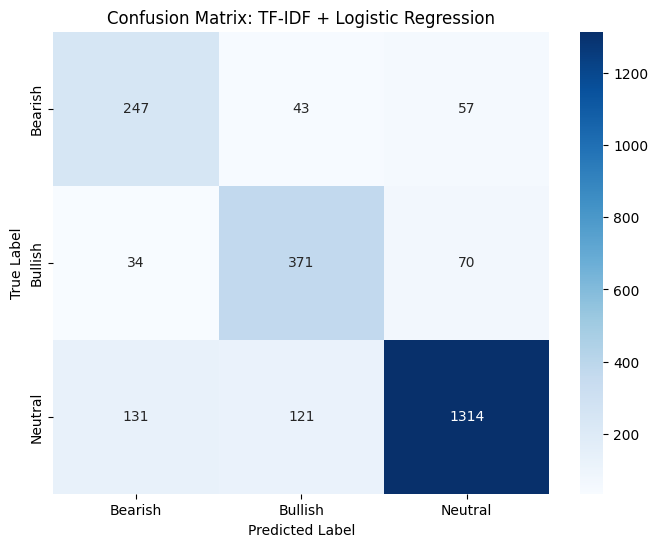

Accuracy: 0.809 | Macro F1: 0.753 | Weighted F1: 0.814


In [7]:
manual_features = train_df[feature_columns].values
manual_features_test = test_df[feature_columns].values

scaler = StandardScaler()
manual_features_scaled = scaler.fit_transform(manual_features)
manual_features_test_scaled = scaler.transform(manual_features_test)

X_train_combined = hstack([X_train_tfidf, manual_features_scaled])
X_test_combined = hstack([X_test_tfidf, manual_features_test_scaled])
print(f"Combined feature matrix shape: {X_train_combined.shape}")

best_lr = LogisticRegression(
    C=3,
    penalty='l2',
    solver='saga',
    max_iter=2000,
    class_weight='balanced',
    random_state=42
)
best_lr.fit(X_train_combined, train_df['label'])
y_pred_lr = best_lr.predict(X_test_combined)

report_lr = classification_report(
    test_df['label'], y_pred_lr, 
    target_names=['Bearish', 'Bullish', 'Neutral'], 
    output_dict=True
)
report_lr_df = pd.DataFrame(report_lr).T
report_lr_df['support'] = report_lr_df['support'].round().astype('Int64')
display(report_lr_df[['precision', 'recall', 'f1-score', 'support']].round(3))

cm_lr = confusion_matrix(test_df['label'], y_pred_lr)
plt.figure(figsize=(8, 6))
sns.heatmap(cm_lr, annot=True, fmt='d', cmap='Blues',
            xticklabels=['Bearish', 'Bullish', 'Neutral'],
            yticklabels=['Bearish', 'Bullish', 'Neutral'])
plt.title('Confusion Matrix: TF-IDF + Logistic Regression')
plt.xlabel('Predicted Label')
plt.ylabel('True Label')
plt.show()

accuracy_lr = accuracy_score(test_df['label'], y_pred_lr)
macro_f1_lr = f1_score(test_df['label'], y_pred_lr, average='macro')
weighted_f1_lr = f1_score(test_df['label'], y_pred_lr, average='weighted')

print(f"Accuracy: {accuracy_lr:.3f} | Macro F1: {macro_f1_lr:.3f} | Weighted F1: {weighted_f1_lr:.3f}")


### Model 2: BERT Embeddings + Financial Features (Neural Network)

BERT combined feature shape: (9543, 778)


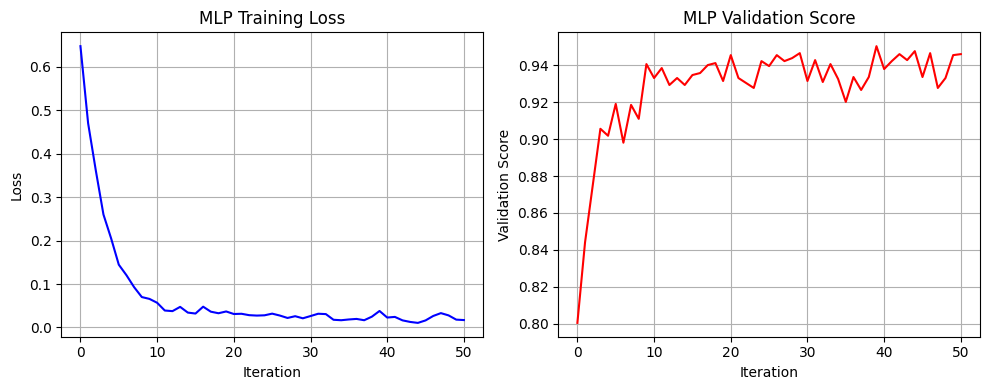

,precision,recall,f1-score,support
Bearish,0.668,0.585,0.624,347
Bullish,0.719,0.642,0.679,475
Neutral,0.847,0.898,0.872,1566
accuracy,0.802,0.802,0.802,1
macro avg,0.745,0.708,0.725,2388
weighted avg,0.796,0.802,0.797,2388


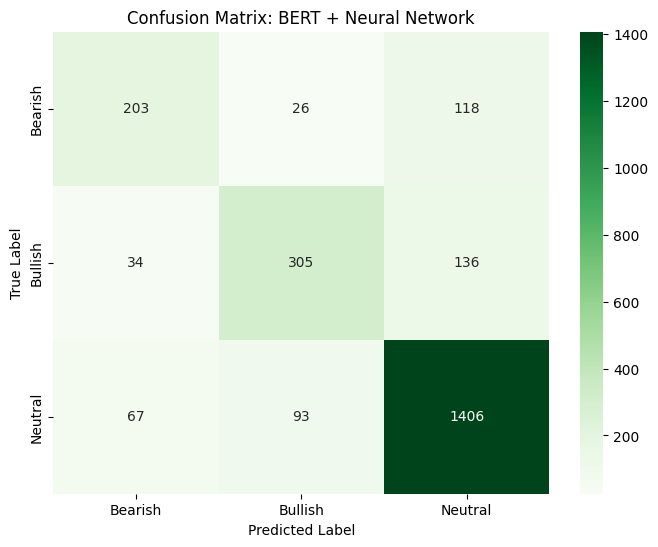

Accuracy: 0.802 | Macro F1: 0.725 | Weighted F1: 0.797


In [8]:
scaler_bert = StandardScaler()
manual_scaled_bert = scaler_bert.fit_transform(manual_features)
manual_scaled_bert_test = scaler_bert.transform(manual_features_test)

X_train_bert_combined = np.hstack([X_train_bert, manual_scaled_bert])
X_test_bert_combined = np.hstack([X_test_bert, manual_scaled_bert_test])
print(f"BERT combined feature shape: {X_train_bert_combined.shape}")

smote = SMOTE(random_state=42, k_neighbors=3)
X_train_balanced, y_train_balanced = smote.fit_resample(X_train_bert_combined, train_df['label'])

mlp = MLPClassifier(
    hidden_layer_sizes=(512, 256, 64),
    activation='relu',
    solver='adam',
    alpha=0.001,
    learning_rate='adaptive',
    learning_rate_init=0.001,
    max_iter=200,
    early_stopping=True,
    validation_fraction=0.1,
    n_iter_no_change=10,
    random_state=42,
    verbose=False
)
mlp.fit(X_train_balanced, y_train_balanced)
y_pred_mlp = mlp.predict(X_test_bert_combined)

plt.figure(figsize=(10, 4))
plt.subplot(1, 2, 1)
plt.plot(mlp.loss_curve_, 'b-')
plt.title('MLP Training Loss')
plt.xlabel('Iteration')
plt.ylabel('Loss')
plt.grid(True)
plt.subplot(1, 2, 2)
plt.plot(mlp.validation_scores_, 'r-')
plt.title('MLP Validation Score')
plt.xlabel('Iteration')
plt.ylabel('Validation Score')
plt.grid(True)
plt.tight_layout()
plt.show()

report_mlp = classification_report(
    test_df['label'], y_pred_mlp, 
    target_names=['Bearish', 'Bullish', 'Neutral'], 
    output_dict=True
)
report_mlp_df = pd.DataFrame(report_mlp).T
report_mlp_df['support'] = report_mlp_df['support'].round().astype('Int64')
display(report_mlp_df[['precision', 'recall', 'f1-score', 'support']].round(3))

cm_mlp = confusion_matrix(test_df['label'], y_pred_mlp)
plt.figure(figsize=(8, 6))
sns.heatmap(cm_mlp, annot=True, fmt='d', cmap='Greens',
            xticklabels=['Bearish', 'Bullish', 'Neutral'],
            yticklabels=['Bearish', 'Bullish', 'Neutral'])
plt.title('Confusion Matrix: BERT + Neural Network')
plt.xlabel('Predicted Label')
plt.ylabel('True Label')
plt.show()

accuracy_mlp = accuracy_score(test_df['label'], y_pred_mlp)
macro_f1_mlp = f1_score(test_df['label'], y_pred_mlp, average='macro')
weighted_f1_mlp = f1_score(test_df['label'], y_pred_mlp, average='weighted')

print(f"Accuracy: {accuracy_mlp:.3f} | Macro F1: {macro_f1_mlp:.3f} | Weighted F1: {weighted_f1_mlp:.3f}")

### ===========================================
# Model Comparison and Evaluation
### ===========================================

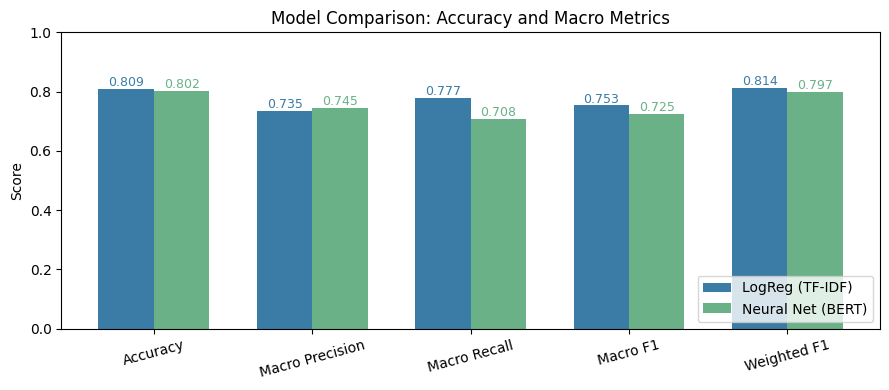

In [9]:
macro_precision_lr = report_lr['macro avg']['precision']
macro_recall_lr    = report_lr['macro avg']['recall']
macro_f1_lr        = report_lr['macro avg']['f1-score']

macro_precision_mlp = report_mlp['macro avg']['precision']
macro_recall_mlp    = report_mlp['macro avg']['recall']
macro_f1_mlp        = report_mlp['macro avg']['f1-score']

weighted_f1_lr = report_lr['weighted avg']['f1-score']
weighted_f1_mlp = report_mlp['weighted avg']['f1-score']

scores = np.array([
    [accuracy_lr, macro_precision_lr, macro_recall_lr, macro_f1_lr, weighted_f1_lr],
    [accuracy_mlp, macro_precision_mlp, macro_recall_mlp, macro_f1_mlp, weighted_f1_mlp]
])
metrics = ['Accuracy', 'Macro Precision', 'Macro Recall', 'Macro F1', 'Weighted F1']
model_names = ['LogReg (TF-IDF)', 'Neural Net (BERT)']

fig, ax = plt.subplots(figsize=(9,4))
bar_width = 0.35
x = np.arange(len(metrics))

ax.bar(x - bar_width/2, scores[0], width=bar_width, label=model_names[0], color='#3a7ca5')
ax.bar(x + bar_width/2, scores[1], width=bar_width, label=model_names[1], color='#6ab187')

ax.set_xticks(x)
ax.set_xticklabels(metrics, rotation=15)
ax.set_ylim(0, 1)
ax.set_ylabel('Score')
ax.set_title('Model Comparison: Accuracy and Macro Metrics')
ax.legend(loc='lower right')

for i in range(len(metrics)):
    ax.text(x[i] - bar_width/2, scores[0][i]+0.01, f"{scores[0][i]:.3f}", ha='center', color='#3a7ca5', fontsize=9)
    ax.text(x[i] + bar_width/2, scores[1][i]+0.01, f"{scores[1][i]:.3f}", ha='center', color='#6ab187', fontsize=9)
plt.tight_layout()
plt.show()